## Qubit Quantum Circuit: End-to-End Qiskit Workflow

Step 1: Map the problem to circuit and operators
In this step, we:
- Define a 12-qubit quantum circuit.
- Apply single-qubit gates and multi-qubit entangling gates.
- Create two 6-qubit GHZ constructions.
- Define 66 pairwise \(ZZ\) observables for correlation analysis.

Number of qubits: 12
Number of ZZ observables: 66


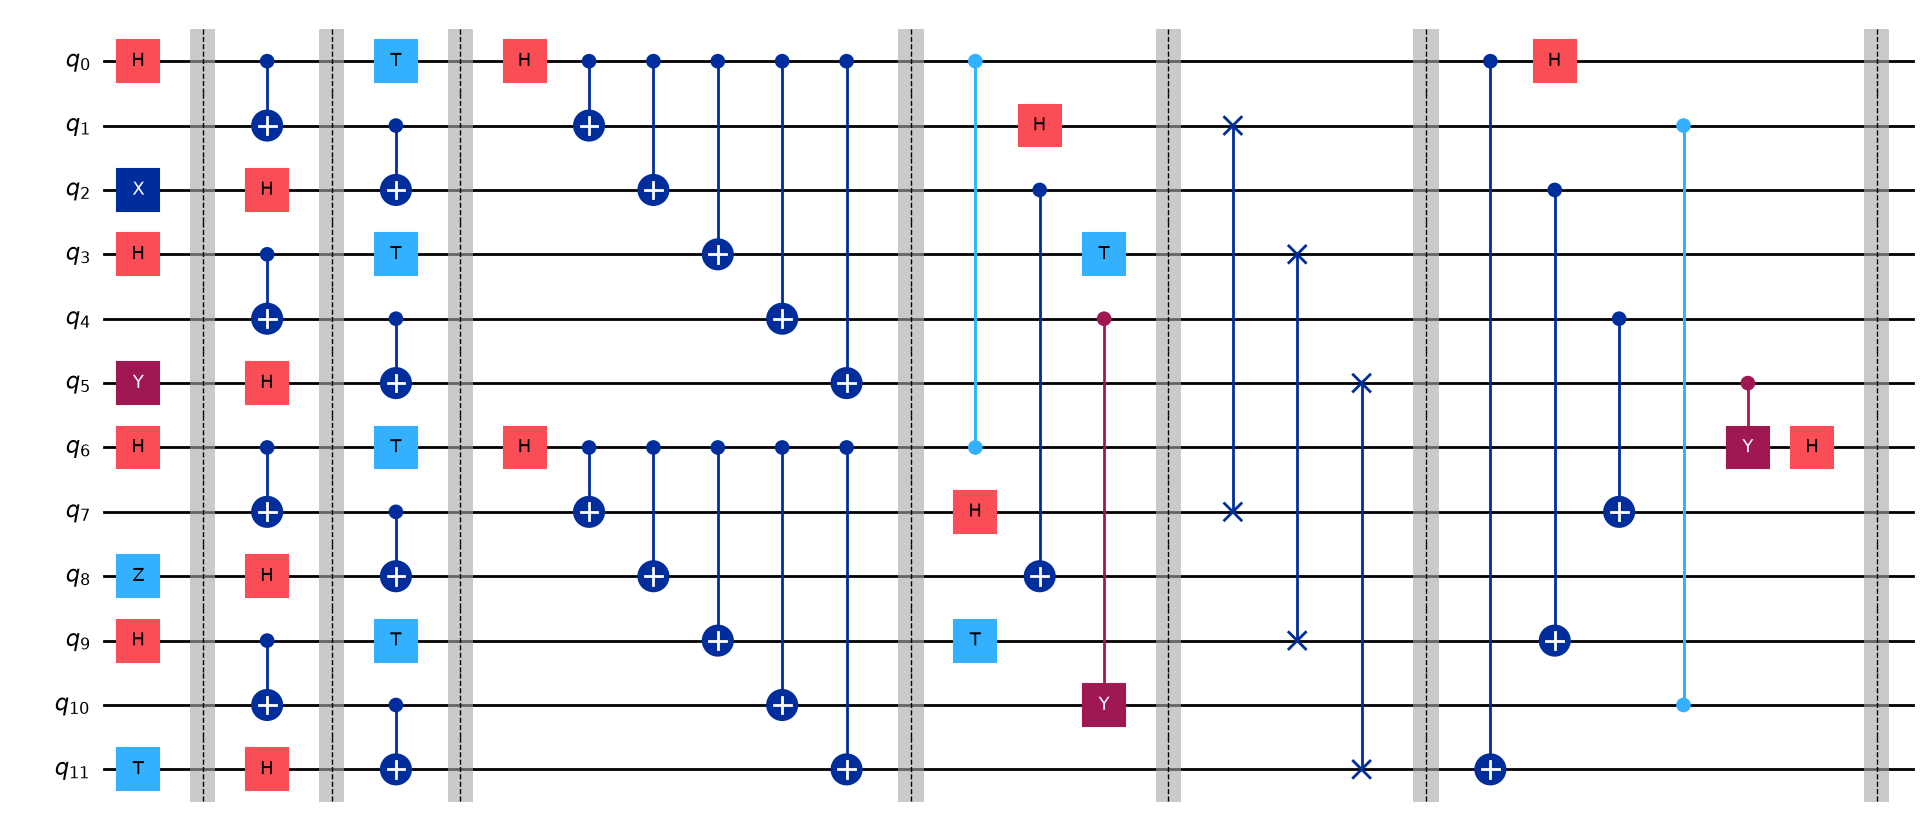

In [1]:
# ==========================================
# STEP 1: MAP THE PROBLEM TO CIRCUIT & OPERATORS
# ==========================================

from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp

# Define 12 qubits
n = 12

# Create quantum circuit with 12 qubits and 12 classical bits
qc = QuantumCircuit(n)

# ------------------------------------------
# LAYER 1: INITIAL SUPERPOSITION
# ------------------------------------------

qc.h(0)
qc.h(3)
qc.h(6)
qc.h(9)

qc.x(2)
qc.y(5)
qc.z(8)
qc.t(11)

qc.barrier()

# ------------------------------------------
# LAYER 2: FIRST ENTANGLEMENT NETWORK
# ------------------------------------------

qc.cx(0, 1)
qc.cx(3, 4)
qc.cx(6, 7)
qc.cx(9, 10)

qc.h(2)
qc.h(5)
qc.h(8)
qc.h(11)

qc.barrier()

# ------------------------------------------
# LAYER 3: INTERLEAVED ENTANGLEMENT
# ------------------------------------------

qc.cx(1, 2)
qc.cx(4, 5)
qc.cx(7, 8)
qc.cx(10, 11)

qc.t(0)
qc.t(3)
qc.t(6)
qc.t(9)

qc.barrier()

# ------------------------------------------
# LAYER 4: GHZ STATE GENERATION
# ------------------------------------------

# First 6-qubit GHZ construction
qc.h(0)
for i in range(1, 6):
    qc.cx(0, i)

# Second 6-qubit GHZ construction
qc.h(6)
for i in range(7, 12):
    qc.cx(6, i)

qc.barrier()

# ------------------------------------------
# LAYER 5: CROSS-GROUP INTERACTIONS
# ------------------------------------------

qc.cz(0, 6)
qc.cx(2, 8)
qc.cy(4, 10)

qc.h(1)
qc.t(3)
qc.h(7)
qc.t(9)

qc.barrier()

# ------------------------------------------
# LAYER 6: STATE EXCHANGE
# ------------------------------------------

qc.swap(1, 7)
qc.swap(3, 9)
qc.swap(5, 11)

qc.barrier()

# ------------------------------------------
# LAYER 7: FINAL ENTANGLEMENT
# ------------------------------------------

qc.cx(0, 11)
qc.cx(2, 9)
qc.cx(4, 7)

qc.cz(1, 10)
qc.cy(5, 6)

qc.h(0)
qc.h(6)

qc.barrier()

# ------------------------------------------
# DEFINE ZZ OBSERVABLES
# ------------------------------------------

# All unique qubit pairs: 12C2 = 66
pairs = [
    (i, j)
    for i in range(n)
    for j in range(i + 1, n)
]

operators = [
    SparsePauliOp.from_sparse_list(
        [("ZZ", [i, j], 1.0)],
        num_qubits=n
    )
    for i, j in pairs
]

print("Number of qubits:", n)
print("Number of ZZ observables:", len(operators))

# Draw circuit
qc.draw("mpl", fold=-1)


Step 2: Optimize the quantum circuit
Here we use Qiskit's transpile() to compile and optimize the circuit for the target backend.

We will:
- Select AerSimulator as the target backend.
- Apply optimization level 3.
- Compare the original and optimized circuit depth.
- Compare the number of gates before and after optimization.

Original Circuit Depth: 13
Optimized Circuit Depth: 12
Original Gate Count: 53
Optimized Gate Count: 50


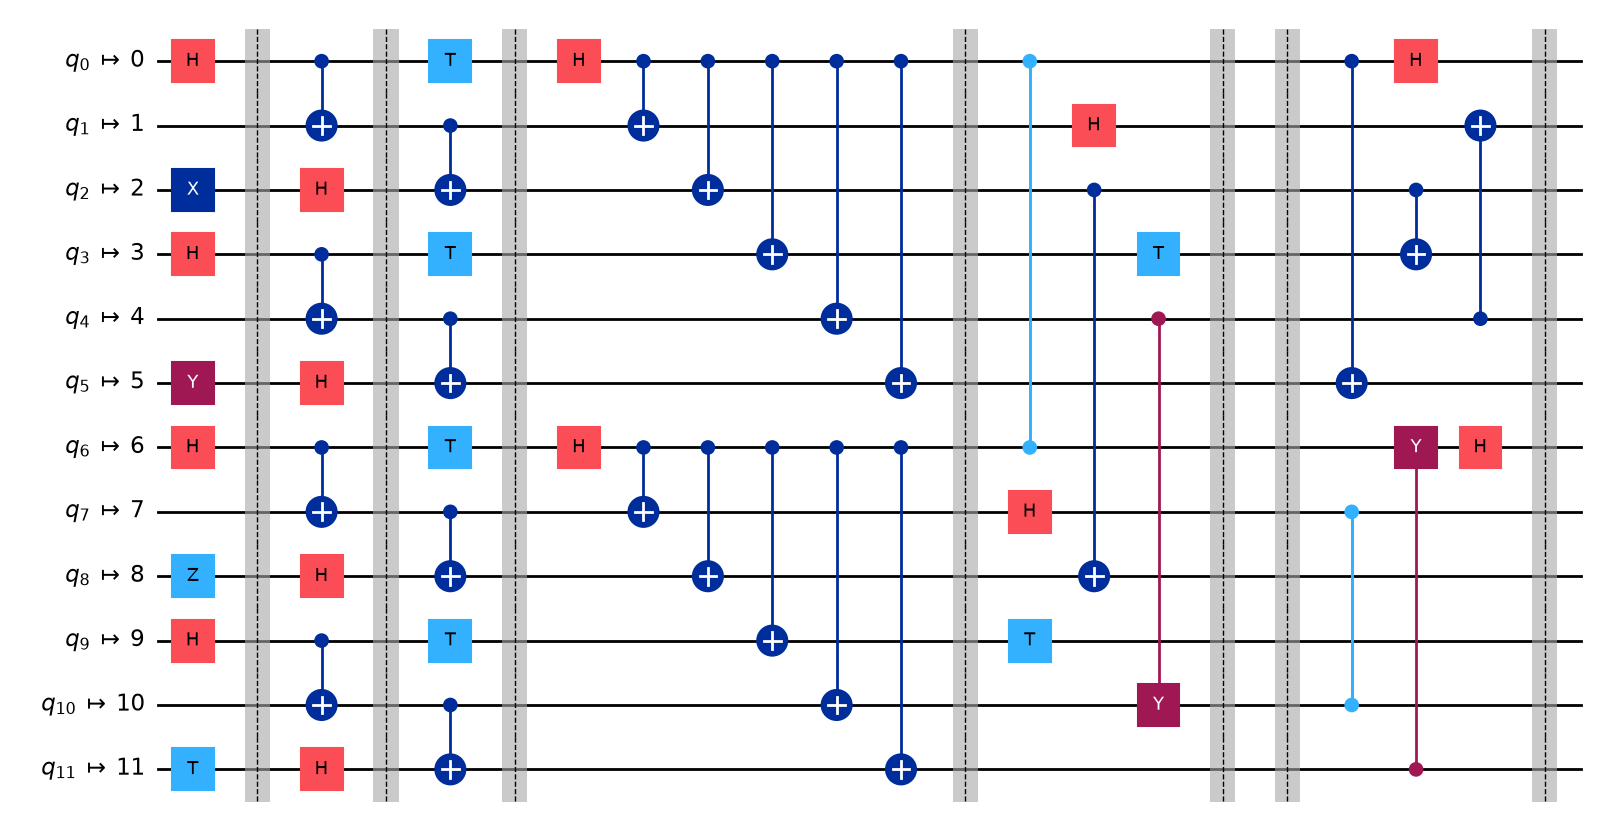

In [2]:
# ==========================================
# STEP 2: OPTIMIZE THE QUANTUM CIRCUIT
# ==========================================

from qiskit import transpile
from qiskit_aer import AerSimulator

# Define simulation backend
backend = AerSimulator()

# Original circuit metrics
original_depth = qc.depth()
original_gates = qc.size()

# Transpile and optimize the circuit
qc_optimized = transpile(
    qc,
    backend=backend,
    optimization_level=3
)

# Optimized circuit metrics
optimized_depth = qc_optimized.depth()
optimized_gates = qc_optimized.size()

print("Original Circuit Depth:", original_depth)
print("Optimized Circuit Depth:", optimized_depth)

print("Original Gate Count:", original_gates)
print("Optimized Gate Count:", optimized_gates)

# Draw optimized circuit
qc_optimized.draw("mpl", fold=-1)


Step 3: Execute on the backend
Now we execute the optimized circuit using two Qiskit execution paths.

A. Estimator — Calculate quantum correlations

The Estimator calculates the expectation values of our 66 \(ZZ\) observables.

B. AerSimulator — Obtain measurement outcomes

The simulator executes the measured circuit using 4096 shots.

In [3]:

from qiskit import QuantumCircuit

# Create a genuinely quantum-only circuit
qc_estimator = QuantumCircuit(n)

# Copy quantum instructions, excluding classical registers
for instruction in qc_optimized.data:

    if instruction.clbits:
        raise ValueError("Unexpected classical operation in circuit")

    qubit_indices = [
        qc_optimized.find_bit(q).index
        for q in instruction.qubits
    ]

    qc_estimator.append(
        instruction.operation,
        [qc_estimator.qubits[i] for i in qubit_indices]
    )

# Preserve global phase
qc_estimator.global_phase = qc_optimized.global_phase

print("Quantum bits:", qc_estimator.num_qubits)
print("Classical bits:", qc_estimator.num_clbits)


Quantum bits: 12
Classical bits: 0


In [4]:
# Execute Estimator 

from qiskit_aer.primitives import Estimator

estimator = Estimator()

estimator_job = estimator.run(
    [qc_estimator] * len(operators),
    operators
)

estimator_result = estimator_job.result()
correlations = estimator_result.values

print("Estimator execution completed")
print("Number of expectation values:", len(correlations))


Estimator execution completed
Number of expectation values: 66


In [5]:
# 3. Execute measurement simulation
from qiskit_aer import AerSimulator

# Create measured circuit
qc_measured = QuantumCircuit(n, n)

qc_measured.compose(
    qc_estimator,
    qubits=range(n),
    inplace=True
)

qc_measured.measure(range(n), range(n))

# Execute on AerSimulator
backend = AerSimulator()

qc_measured = transpile(qc_measured, backend)

simulator_job = backend.run(
    qc_measured,
    shots=4096
)

simulator_result = simulator_job.result()
counts = simulator_result.get_counts()

print("Simulation completed")
print("Total shots:", sum(counts.values()))
print("Unique outcomes:", len(counts))


Simulation completed
Total shots: 4096
Unique outcomes: 894


Step 4: Post-process and plot the results
Now we use Python libraries to process the results returned by Qiskit.

We will create three visualizations.

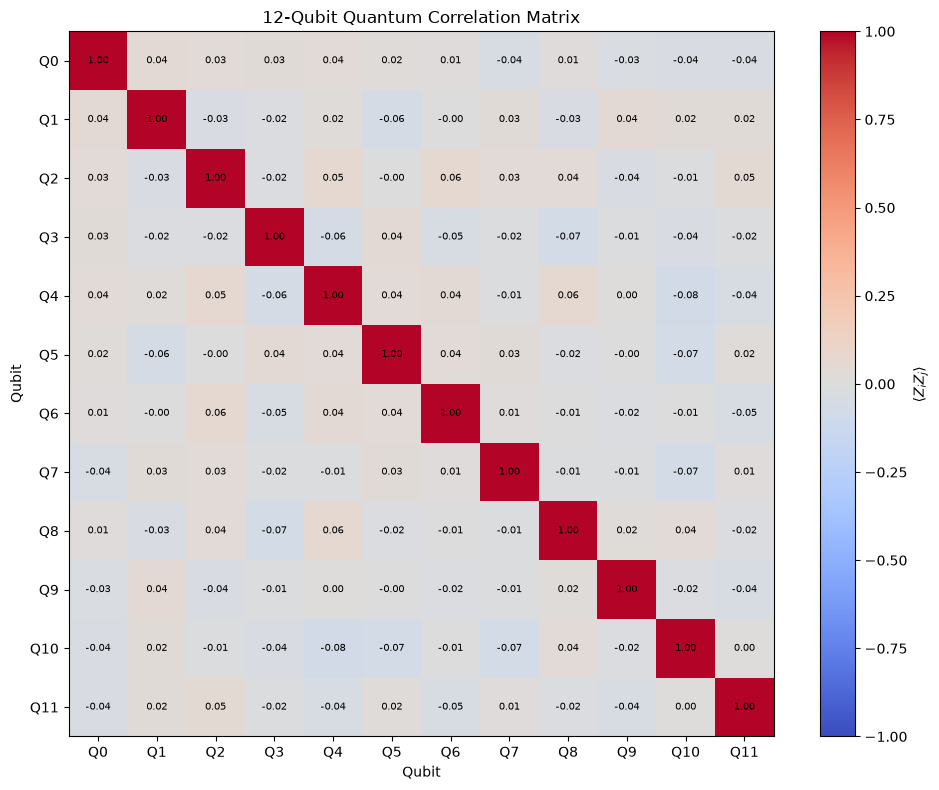

In [6]:
# A. Quantum correlation heatmap


# ==========================================
# STEP 4: POST-PROCESS AND PLOT
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------
# A. CORRELATION MATRIX
# ------------------------------------------

corr_matrix = np.eye(n)

for (i, j), value in zip(pairs, correlations):
    corr_matrix[i, j] = value
    corr_matrix[j, i] = value

plt.figure(figsize=(10, 8))

plt.imshow(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label=r'$\langle Z_i Z_j \rangle$')

plt.xticks(range(n), [f'Q{i}' for i in range(n)])
plt.yticks(range(n), [f'Q{i}' for i in range(n)])

plt.title("12-Qubit Quantum Correlation Matrix")
plt.xlabel("Qubit")
plt.ylabel("Qubit")

for i in range(n):
    for j in range(n):
        plt.text(
            j, i,
            f"{corr_matrix[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=7
        )

plt.tight_layout()
plt.show()


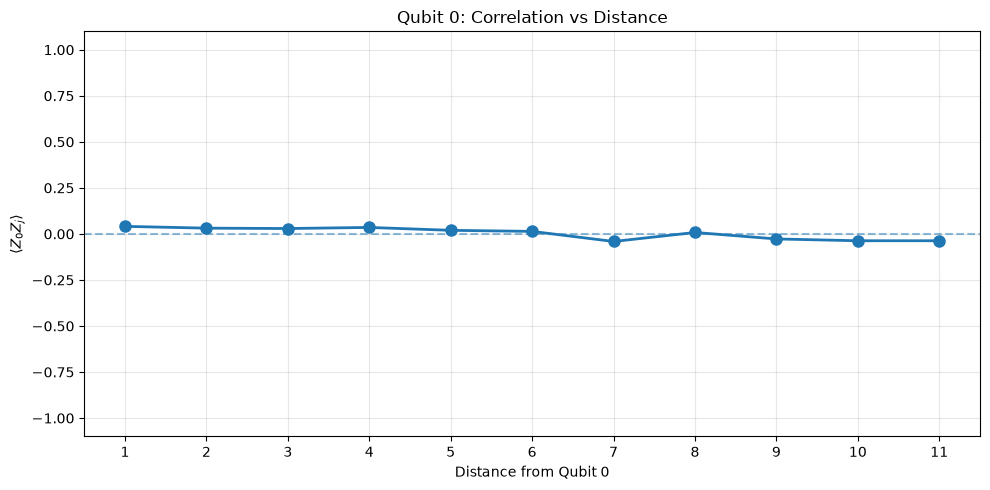

In [7]:
# B. Correlation versus distance


# ------------------------------------------
# B. CORRELATION VS DISTANCE
# ------------------------------------------

distances = np.arange(1, n)

correlation_values = [
    corr_matrix[0, j]
    for j in distances
]

plt.figure(figsize=(10, 5))

plt.plot(
    distances,
    correlation_values,
    marker='o',
    linewidth=2,
    markersize=8
)

plt.axhline(0, linestyle='--', alpha=0.5)

plt.xticks(distances)
plt.ylim(-1.1, 1.1)

plt.xlabel("Distance from Qubit 0")
plt.ylabel(r'$\langle Z_0 Z_j \rangle$')

plt.title("Qubit 0: Correlation vs Distance")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


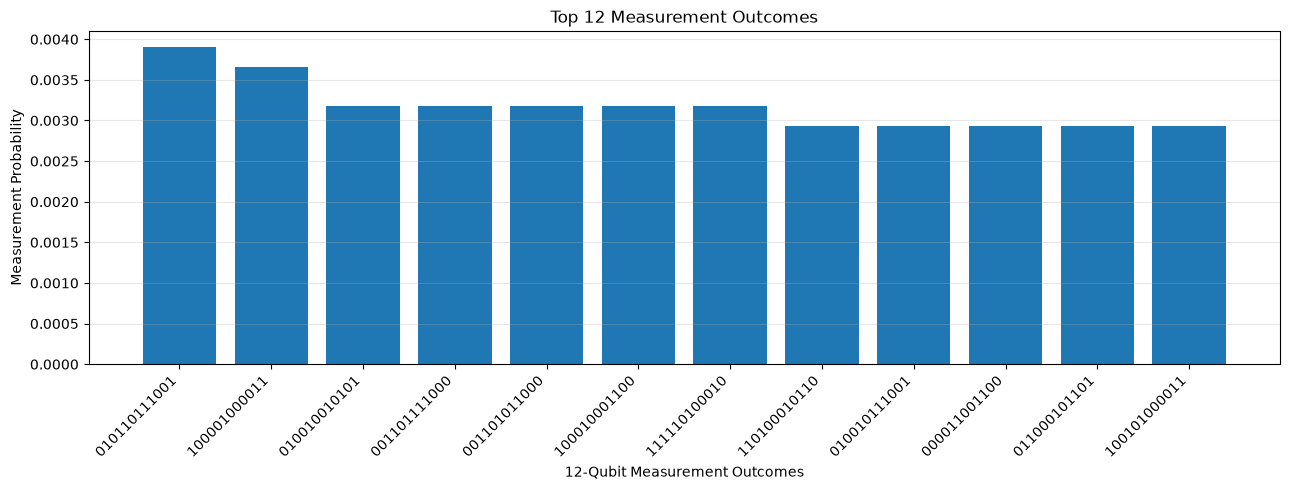

In [8]:
# C. Measurement probability distribution


# ------------------------------------------
# C. MEASUREMENT DISTRIBUTION
# ------------------------------------------

# Select top 12 measurement outcomes
top_counts = sorted(
    counts.items(),
    key=lambda x: x[1],
    reverse=True
)[:12]

labels = [item[0] for item in top_counts]
values = [item[1] for item in top_counts]

# Convert counts to probabilities
probabilities = [
    value / sum(counts.values())
    for value in values
]

plt.figure(figsize=(13, 5))

plt.bar(labels, probabilities)

plt.xlabel("12-Qubit Measurement Outcomes")
plt.ylabel("Measurement Probability")

plt.title("Top 12 Measurement Outcomes")

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
